# In this notebook: 
we build a simple feed-forward **Artificial Neural Network (ANN)** using Keras to predict customer feedback **Priority** (`Low`, `Medium`, `High`) and compare it with our traditional Logistic Regression baseline.

### Conceptual Overview
- **Input Layer**: Receives numerical features (TF-IDF word vectors + one-hot encoded categorical columns + scaled numerical columns).
- **Hidden Dense Layers (`ReLU`)**: Learn non-linear combinations of features. `ReLU` ($f(x) = \max(0, x)$) keeps positive signals and avoids vanishing gradients.
- **Dropout Layer**: Randomly turns off a fraction of neurons during training to reduce overfitting.
- **Output Layer (`Softmax`)**: Outputs probabilities across the 3 priority classes (`Low`, `Medium`, `High`) that sum to 1.
- **Loss Function (`sparse_categorical_crossentropy`)**: Measures how far predicted class probabilities are from the true integer class label.
- **Optimizer (`Adam`)**: Updates neural network weights efficiently during **backpropagation** after each **forward propagation** pass.

In [1]:
import re
import string
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

In [2]:
# 1. Load & Clean Data
def clean_text(text):
    text = str(text).lower()
    text = text.translate(str.maketrans("", "", string.punctuation))
    text = re.sub(r"\d+", "", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df = pd.read_csv("../data/customer_feedback.csv")
df["clean_text"] = df["feedback_text"].apply(clean_text)

train_df, test_df = train_test_split(
    df, test_size=0.2, random_state=42, stratify=df["priority"]
)

In [3]:
# 2. Preprocess Features & Labels for Keras ANN
feature_cols = ["clean_text", "channel", "customer_type", "order_value", "days_as_customer"]

ann_preprocessor = ColumnTransformer([
    ("text", TfidfVectorizer(max_features=1500, ngram_range=(1, 2)), "clean_text"),
    ("cat", OneHotEncoder(handle_unknown="ignore"), ["channel", "customer_type"]),
    ("num", StandardScaler(), ["order_value", "days_as_customer"])
])

X_train = ann_preprocessor.fit_transform(train_df[feature_cols]).toarray()
X_test = ann_preprocessor.transform(test_df[feature_cols]).toarray()

label_encoder = LabelEncoder()
y_train = label_encoder.fit_transform(train_df["priority"])
y_test = label_encoder.transform(test_df["priority"])

print("X_train shape:", X_train.shape)
print("Classes:", label_encoder.classes_)

X_train shape: (24000, 1352)
Classes: ['High' 'Low' 'Medium']


In [4]:
# 3. Build Feed-Forward Keras ANN
model = keras.Sequential([
    layers.Input(shape=(X_train.shape[1],)),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(3, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 128)                 │         173,184 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 3)                   │             195 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 181,635 (709.51 KB)

 Trainable params: 181,635 (709.51 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
# 4. Train the ANN
early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)

history = model.fit(
    X_train, y_train,
    validation_split=0.15,
    epochs=15,
    batch_size=128,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/15
160/160 ━━━━━━━━━━━━━━━━━━━━ 8s 27ms/step - accuracy: 0.4722 - loss: 1.0296 - val_accuracy: 0.4769 - val_loss: 1.0157
Epoch 2/15
160/160 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.4940 - loss: 1.0069 - val_accuracy: 0.4769 - val_loss: 1.0148
Epoch 3/15
160/160 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.4972 - loss: 1.0009 - val_accuracy: 0.4750 - val_loss: 1.0166
Epoch 4/15
160/160 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.5030 - loss: 0.9975 - val_accuracy: 0.4700 - val_loss: 1.0184
Epoch 5/15
160/160 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.5053 - loss: 0.9934 - val_accuracy: 0.4739 - val_loss: 1.0205


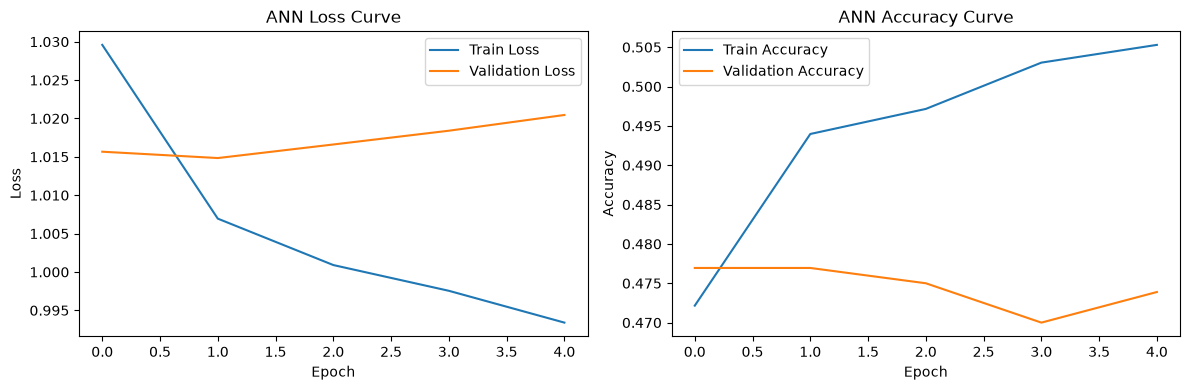

In [6]:
# 5. Plot Training & Validation Loss / Accuracy
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history["loss"], label="Train Loss")
axes[0].plot(history.history["val_loss"], label="Validation Loss")
axes[0].set_title("ANN Loss Curve")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].plot(history.history["accuracy"], label="Train Accuracy")
axes[1].plot(history.history["val_accuracy"], label="Validation Accuracy")
axes[1].set_title("ANN Accuracy Curve")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step
Keras ANN Test Accuracy: 0.485

Classification Report:
               precision    recall  f1-score   support

        High       0.52      0.61      0.56      1980
         Low       0.49      0.66      0.56      2040
      Medium       0.38      0.19      0.25      1980

    accuracy                           0.48      6000
   macro avg       0.46      0.48      0.46      6000
weighted avg       0.47      0.48      0.46      6000



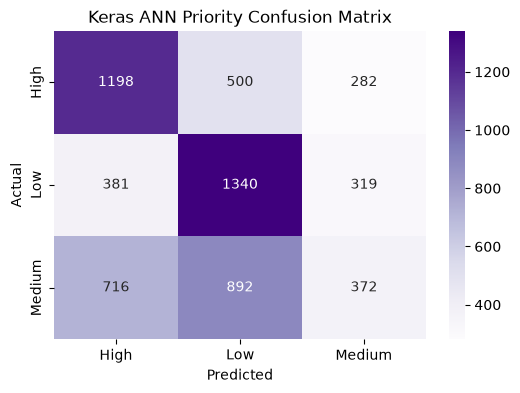

In [7]:
# 6. Evaluate ANN vs Traditional ML Baseline
y_probs = model.predict(X_test)
y_pred = np.argmax(y_probs, axis=1)

ann_acc = accuracy_score(y_test, y_pred)
print("Keras ANN Test Accuracy:", round(ann_acc, 4))
print("\nClassification Report:\n", classification_report(y_test, y_pred, target_names=label_encoder.classes_))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Purples", xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.title("Keras ANN Priority Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [8]:
# 7. Save Keras Model and Preprocessor for Streamlit App
model.save("../models/priority_ann.keras")
joblib.dump(ann_preprocessor, "../models/priority_preprocessor.pkl")
joblib.dump(label_encoder, "../models/priority_encoder.pkl")

print("Saved priority_ann.keras, priority_preprocessor.pkl, and priority_encoder.pkl successfully!")

Saved priority_ann.keras, priority_preprocessor.pkl, and priority_encoder.pkl successfully!
